# 15 Fallsammlung: Begehungen im Ternärbild

Teil 4: Stationsbilder und Befunde

**Worum es geht**
- Wo zeigt das Ternärbild eine bessere Effizienz, und fällt sie mit einer Begehung zusammen?
- Anschluss an Notebook 11: welche Stationen verschieben ihre Effizienz, und wie verhalten sich Stationen ohne Begehung?
- Taugt der Vergleich der Stationen untereinander? Bis auf eine Schule sind alles Wohnhäuser.
- Maßstab sind Effektstärken und Häufigkeiten. Bei 93 Stationen und 66 Begehungen ist Signifikanz nicht zu erwarten.

**Daten**
- liest: Stundenreihen in `data/processed/real_meters`, Begehungstabelle mit Freitexten
- schreibt: `outputs/fallsammlung/` (`vorschlagsliste.csv`, `wirkung_winter.csv`, `querschnitt_winter.csv` und drei Abbildungen)
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/fallsammlung.py`, `src/ternaer.py` und `src/befundcodes.py`, Tests in `tests/test_fallsammlung.py` und `tests/test_befundcodes.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import fallsammlung as fs
from src import load_begehungen as lb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
OUT_DIR = ROOT / "outputs" / "fallsammlung"
OUT_DIR.mkdir(parents=True, exist_ok=True)

t0 = time.time()


def tick(txt):
    print(f"[{time.time() - t0:6.0f}s] {txt}", flush=True)

## 1 Gruppen bilden

- Begehungsgruppe: Stationen mit Termin in der Begehungstabelle.
- Kontrollgruppe: Stationen ohne Begehung. Sie bekommen ein Pseudodatum aus der Verteilung der echten Termine, also dasselbe Kalenderfenster.
- Fünf Begehungen ohne Datum fallen aus beiden Gruppen heraus.

In [2]:
serien = tn.lade_serien(METER_DIR)
termine = lb.begehung_dates_by_meter(available=set(serien))
begehungsdatum = {m: sorted(d)[0] for m, d in termine.items() if d}

beg_alle = lb.begehungen_mit_zaehler()
ohne_datum = ((set(beg_alle["meter"].dropna().astype(int))
               - set(begehungsdatum)) & set(serien))
kontrolle = fs.kontrollgruppe(serien, begehungsdatum, ausschluss=ohne_datum)

datum = {**begehungsdatum, **kontrolle}
tick(f"{len(serien)} Zaehlerreihen")
print(f"Begehungsgruppe {len(begehungsdatum)}, Kontrollgruppe {len(kontrolle)}, "
      f"ohne Datum und deshalb ausgeschlossen {len(ohne_datum)}")
print(f"ausgeschlossene Zaehler: {sorted(ohne_datum)}")

[     1s] 93 Zaehlerreihen


Begehungsgruppe 56, Kontrollgruppe 37, ohne Datum und deshalb ausgeschlossen 5
ausgeschlossene Zaehler: [65273846, 68956347, 72135481, 72167782, 80912202]


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 2 Warum saisongleich verglichen wird

- Gemessen wird die Performance: Wärme je Kubikmeter Wasser in kWh/m³. Höher heißt: dieselbe Wärme mit weniger Wasser.
- Der Schnitt in `src/ternaer.py` teilt die ganze Historie am Begehungsdatum. Fast alle Termine liegen im Spätsommer und Herbst 2024, also stehen zwei bis drei Jahre Vorher gegen einen Winter Nachher.
- Der Rücklauf ist im Winter systematisch anders. Der naive Vergleich misst also zum Teil die Jahreszeit.
- Deshalb zusätzlich der Winterschnitt: Winterstunden vorher gegen Winterstunden nachher.

In [3]:
begangen = set(begehungsdatum)
effekt = {}
for name, saison in (("naiv", None), ("winter", tn.GRUPPE_WINTER)):
    effekt[name] = fs.effekt_je_station(serien, datum, begangen, saison=saison)
    tick(f"Schnitt {name}: {len(effekt[name])} Stationen")

vergleich = []
for name, tab in effekt.items():
    t = tab[tab["genug"]]
    for gruppe, teil in (("Begehung", t[t["begehung"]]),
                         ("Kontrolle", t[~t["begehung"]])):
        s = teil["d_perf"].dropna()
        vergleich.append({"schnitt": name, "gruppe": gruppe, "n": len(s),
                          "median": round(float(s.median()), 2),
                          "mittel": round(float(s.mean()), 2),
                          "anteil_positiv": round(float((s > 0).mean()), 2)})
print(pd.DataFrame(vergleich).to_string(index=False))

[     2s] Schnitt naiv: 88 Stationen


[     3s] Schnitt winter: 88 Stationen


schnitt    gruppe  n  median  mittel  anteil_positiv
   naiv  Begehung 44   -0.29    0.95            0.45
   naiv Kontrolle 31    1.28    2.46            0.55
 winter  Begehung 42    0.81    1.16            0.52
 winter Kontrolle 28   -0.76    1.31            0.39


- Naiv liegt die Kontrollgruppe vorn (Median +1,28 gegen −0,29). Im Winterschnitt dreht es sich um (−0,76 gegen +0,81).
- Alles Weitere läuft über den Winterschnitt.

In [4]:
winter = effekt["winter"]
winter = winter[winter["genug"]].copy()

kodiert = bc.kodiere_begehungen()
labels = bc.labels_je_zaehler(kodiert)
winter = fs.markiere_mechanisch(winter, labels)

notiz = (beg_alle.dropna(subset=["sonstiges"]).groupby("meter")["sonstiges"]
         .apply(lambda s: " | ".join(str(x) for x in s)))
winter["notiz"] = winter["meter"].map(notiz)

winter["lage"] = np.where(~winter["begehung"], "ohne Begehung",
                          np.where(winter["mechanisch"],
                                   "Begehung, mechanisch",
                                   "Begehung, kein mechanischer Befund"))
print(winter["lage"].value_counts().to_string())

lage
ohne Begehung                         28
Begehung, kein mechanischer Befund    27
Begehung, mechanisch                  15


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 3 Wirkung je Gruppe

- Mechanisch: der Freitext nennt Schmutzfänger, Ventil oder Stellantrieb, Pumpe, Zirkulation oder Volumenstrom (Kodierung aus Notebook 14).
- Nur ein solcher Eingriff sollte das Verhältnis von Leistung zu Durchfluss verschieben.
- Effektstärke Cliffs Delta: wie oft ein Wert der einen Gruppe größer ist als einer der anderen, Wertebereich −1 bis +1.

In [5]:
print("Aenderung der Performance im Winter, in kWh/m3")
print(fs.gruppenvergleich(winter, "lage").round(2).to_string(index=False))
print()

mech = winter[winter["lage"] == "Begehung, mechanisch"]["d_perf"].dropna()
nmech = winter[winter["lage"] == "Begehung, kein mechanischer Befund"]["d_perf"].dropna()
kon = winter[winter["lage"] == "ohne Begehung"]["d_perf"].dropna()

for name, x, y in (("mechanisch gegen nicht mechanisch", mech, nmech),
                   ("mechanisch gegen Kontrolle", mech, kon),
                   ("nicht mechanisch gegen Kontrolle", nmech, kon)):
    d = fs.cliffs_delta(x, y)
    p = stats.mannwhitneyu(x, y, alternative="two-sided").pvalue
    print(f"{name:36s} Cliffs delta {d:+.3f}   (p = {p:.3f})")

Aenderung der Performance im Winter, in kWh/m3
                            gruppe  n  median  mittel  anteil_positiv
Begehung, kein mechanischer Befund 27   -0.35   -0.99            0.48
              Begehung, mechanisch 15    1.51    5.02            0.60
                     ohne Begehung 28   -0.76    1.31            0.39

mechanisch gegen nicht mechanisch    Cliffs delta +0.358   (p = 0.059)
mechanisch gegen Kontrolle           Cliffs delta +0.229   (p = 0.226)
nicht mechanisch gegen Kontrolle     Cliffs delta -0.111   (p = 0.485)


- Reihenfolge wie erwartet: mechanisch (Median +1,51) vor Begehung ohne mechanischen Befund (−0,35) vor keiner Begehung (−0,76).
- Zwischen den beiden Begehungsgruppen Cliffs Delta rund 0,36 (p = 0,059) bei 15 gegen 27 Stationen. Das ist ein Muster, kein Beweis. Die übrigen Vergleiche liegen klar über p = 0,05.
- Ohne Begehung verschlechtert sich die Mehrheit leicht.

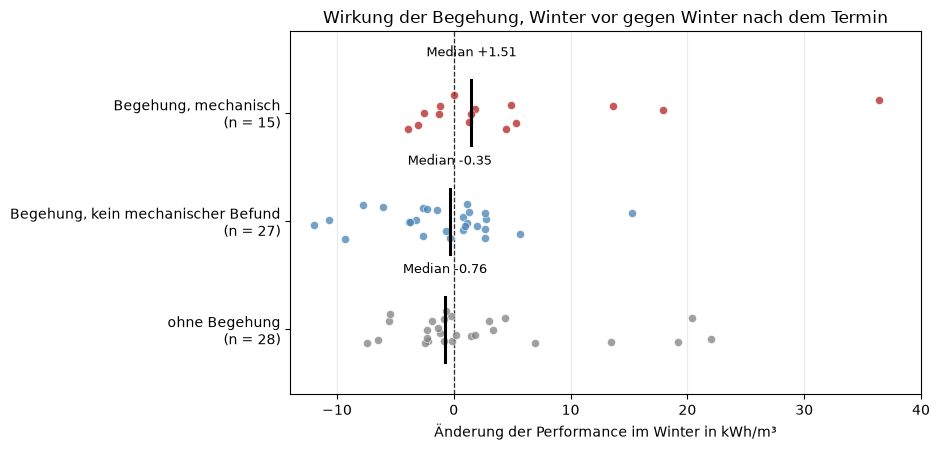

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
reihen = ["Begehung, mechanisch", "Begehung, kein mechanischer Befund",
          "ohne Begehung"]
farben = ["firebrick", "steelblue", "grey"]
rng = np.random.default_rng(1)
for i, (name, farbe) in enumerate(zip(reihen, farben)):
    s = winter[winter["lage"] == name]["d_perf"].dropna()
    y = i + rng.uniform(-0.17, 0.17, len(s))
    ax.scatter(s, y, s=34, color=farbe, alpha=0.75, edgecolor="white",
               linewidth=0.5, zorder=3)
    ax.plot([s.median(), s.median()], [i - 0.3, i + 0.3], color="black",
            lw=2.2, zorder=4)
    ax.text(s.median(), i - 0.52, f"Median {s.median():+.2f}", ha="center",
            fontsize=9)
ax.axvline(0, color="black", lw=0.9, ls="--", zorder=1)
ax.set_yticks(range(len(reihen)))
ax.set_yticklabels([f"{n}\n(n = {int((winter['lage'] == n).sum())})"
                    for n in reihen])
ax.set_ylim(-0.75, len(reihen) - 0.4)
ax.invert_yaxis()
ax.set_xlabel("Änderung der Performance im Winter in kWh/m³")
ax.set_title("Wirkung der Begehung, Winter vor gegen Winter nach dem Termin")
ax.grid(axis="x", alpha=0.25)
ax.set_xlim(-14, 40)
fig.tight_layout()
fig.savefig(OUT_DIR / "wirkung_je_gruppe.png", dpi=120)
plt.show()

- Der Punkt bei +36 ist Zähler 68956351 (Ventil über Jahre offen). Er zieht den Mittelwert hoch, deshalb zählt der Median.

## 4 Die Fälle einzeln

- Alle Stationen mit mechanischem Befund, sortiert nach gemessener Wirkung.

In [7]:
sp = ["meter", "datum", "perf_vorher", "perf_nachher", "d_perf", "n_befunde"]
fall = winter[winter["mechanisch"]].sort_values("d_perf", ascending=False)
print(fall[sp].round(2).to_string(index=False))
print()
for _, r in fall.iterrows():
    print(f"{int(r['meter'])} {r['d_perf']:+7.2f}  {str(r['notiz'])[:90]}")

   meter      datum  perf_vorher  perf_nachher  d_perf  n_befunde
68956351 2024-09-09         3.61         40.01   36.40        2.0
69527345 2024-09-17        22.91         40.82   17.91        1.0
68956355 2024-09-16        32.56         46.17   13.61        1.0
80912189 2024-09-19        40.01         45.36    5.35        1.0
80912193 2024-11-05        30.70         35.59    4.88        2.0
68956345 2024-09-18        24.66         29.13    4.48        1.0
72167784 2024-09-12        32.91         34.77    1.86        1.0
80912178 2024-09-23        24.54         26.05    1.51        2.0
80912162 2024-09-16        36.29         37.56    1.28        2.0
80912159 2024-09-10        35.70         35.70    0.00        1.0
80912182 2024-09-19         8.72          7.56   -1.16        1.0
80912156 2024-09-25        46.40         45.12   -1.28        1.0
68956339 2024-11-25        30.01         27.45   -2.56        2.0
72135442 2024-09-12        19.07         16.05   -3.02        1.0
68956353 2

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37707/4239449123.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(fall[sp].round(2).to_string(index=False))


- Oben stehen getauschte oder gangbar gemachte Regelventile und ein stark verschmutzter Schmutzfänger. Unten eher Zustandsbeschreibungen.
- Ausreißer 72135442 und 68956353: Eingriff im Text, Messung schlechter. 68956353 lag vorher schon bei 49 kWh/m³.
- Unten die Gegenrichtung: Begehungen ohne mechanischen Befund mit der stärksten Verschlechterung.

In [8]:
flop = winter[winter["begehung"] & ~winter["mechanisch"]].nsmallest(6, "d_perf")
for _, r in flop.iterrows():
    print(f"{int(r['meter'])} {r['d_perf']:+7.2f}  {str(r['notiz'])[:90]}")

80912173  -11.98  EG Fußboden OG Radiator Keller sporadisch beheizt 1990 BJ 
80912190  -10.70  Nur Fußboden BJ 2016
68956372   -9.30  nan
80912195   -7.73  Nippel eingeprüft wurde als Defekt gekennzeichnet nachprüfen
80912169   -6.05  WW+Heizkreis Heizkörper
80912164   -3.84  von 60 m^2 auf 170 m^2 oben Fußbodenheizung unten radiatoren 


- Die Notizen beschreiben meist das Haus (Heizkörperart, Baujahr, Wohnfläche), keine Reparatur.
- 80912164: Fläche von 60 auf 170 m² erweitert. Das passt zur schlechteren Kennzahl ohne Defekt.
- 80912195: Defekt nur vermerkt, nicht behoben.

## 5 Vorzeigefälle im Ternärbild

- Ternärbild: Punktwolke im Dreieck aus Leistung, Volumenstrom und Spreizung (Vorlauf minus Rücklauf), gefärbt nach Performance (Notebook 11).
- Drei mechanische Fälle mit klarer Wirkung, Winterstunden vor und nach der Begehung.

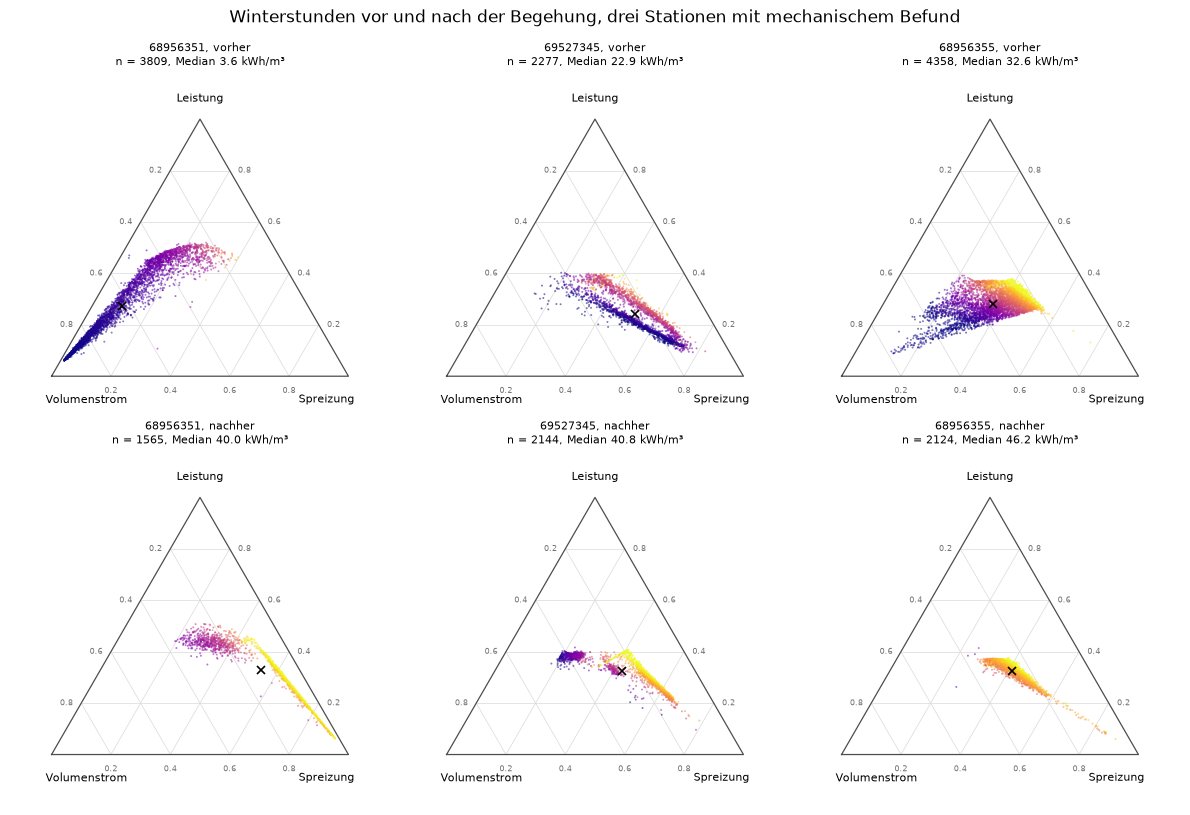

In [9]:
VORZEIGE = [68956351, 69527345, 68956355]

fig, axes = plt.subplots(2, len(VORZEIGE), figsize=(4.0 * len(VORZEIGE), 8.2))
for spalte, meter in enumerate(VORZEIGE):
    tab = tn.stationstabelle(serien[meter], meter,
                             begehungsdatum=begehungsdatum[meter])
    tab = tab[tab["gruppe_saison"] == tn.GRUPPE_WINTER]
    #gemeinsame Farbskala je Station, sonst ist vorher/nachher nicht vergleichbar
    vmin, vmax = tab["performance"].quantile([0.05, 0.95])
    for zeile, gruppe in enumerate([tn.GRUPPE_VORHER, tn.GRUPPE_NACHHER]):
        ax = axes[zeile, spalte]
        teil = tab[tab["gruppe_begehung"] == gruppe]
        tn.zeichne_panel(ax, teil, f"{meter}, {gruppe}",
                         vmin=float(vmin), vmax=float(vmax))
fig.suptitle("Winterstunden vor und nach der Begehung, drei Stationen "
             "mit mechanischem Befund", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "vorzeigefaelle_ternaer.png", dpi=120)
plt.show()

- Die Wolke rutscht jeweils von der Volumenstromecke zur Spreizungsecke und wird heller: dieselbe Wärme mit weniger Wasser.
- Am deutlichsten bei 68956351, derselben Station mit dem Kennliniensprung in Notebook 12.
- Die Lage im Dreieck zeigt die mittlere Aufteilung, der Modulationsanteil den Kanal, über den sich die Leistung ändert.

## 6 Stationen, die sich ohne Begehung verändert haben

- Gegenprobe: sonst sieht jede Veränderung nach Wirkung aus.

In [10]:
kand = winter[~winter["begehung"] & (winter["d_perf"] > 5)].sort_values(
    "d_perf", ascending=False)
print(f"Kontrollstationen mit Steigerung ueber 5 kWh/m3: {len(kand)} von "
      f"{int((~winter['begehung']).sum())}")
print(kand[["meter", "datum", "perf_vorher", "perf_nachher", "d_perf"]]
      .round(2).to_string(index=False))
print()
mit = winter[winter["begehung"] & (winter["d_perf"] > 5)]
print(f"Begehungsstationen mit Steigerung ueber 5 kWh/m3: {len(mit)} von "
      f"{int(winter['begehung'].sum())}")

m2a = lb.meter_to_address()
adressen_mit_begehung = {m2a.get(int(m)) for m in beg_alle["meter"].dropna()}
for _, r in kand.iterrows():
    adr = m2a.get(int(r["meter"]))
    print(f"  {int(r['meter'])}: Adresse zugeordnet "
          f"{'ja' if adr else 'nein'}, Begehung an dieser Adresse "
          f"{'ja' if adr in adressen_mit_begehung else 'nein'}")

Kontrollstationen mit Steigerung ueber 5 kWh/m3: 5 von 28
   meter      datum  perf_vorher  perf_nachher  d_perf
69513891 2024-09-20        19.77         41.75   21.98
72167777 2024-11-19         5.76         26.17   20.41
80912185 2024-09-23        19.89         39.08   19.19
68956361 2024-11-05        27.45         40.94   13.49
80912158 2024-09-11        37.51         44.43    6.92

Begehungsstationen mit Steigerung ueber 5 kWh/m3: 6 von 42
  69513891: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  72167777: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  80912185: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  68956361: Adresse zugeordnet ja, Begehung an dieser Adresse nein
  80912158: Adresse zugeordnet ja, Begehung an dieser Adresse nein


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37707/1653150520.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2).to_string(index=False))


- 5 von 31 Kontrollstationen verbessern sich um mehr als 5 kWh/m³, in der Begehungsgruppe 7 von 41. Die Quote ist ähnlich.
- Keine der fünf steht in der Begehungstabelle. Möglich sind eine nicht protokollierte Reparatur oder eine geänderte Nutzung.
- Eine Verbesserung allein belegt also keine Begehung.

## 7 Stationen untereinander vergleichen

- Findet die Ternärkennzahl auffällige Stationen auch ohne Begehung?
- Querschnitt über alle Stationen mit mindestens 200 Winterstunden.

In [11]:
zeilen = []
for meter, df in sorted(serien.items()):
    tab = tn.stationstabelle(df, meter)
    if len(tab) == 0:
        continue
    w = tab[tab["gruppe_saison"] == tn.GRUPPE_WINTER]
    if len(w) < 200:
        continue
    zeile = tn.kennzahlen(w, "gruppe_saison", [tn.GRUPPE_WINTER],
                          meter=meter).iloc[0].to_dict()
    zeile["leistung_p95"] = float(w["power_kw"].quantile(0.95))
    zeile["stunden_winter"] = int(len(w))
    zeilen.append(zeile)

quer = pd.DataFrame(zeilen)
quer["begehung"] = quer["meter"].isin(set(beg_alle["meter"].dropna().astype(int)))
tick(f"Querschnitt ueber {len(quer)} Stationen mit genug Winterstunden")
print(quer[["performance_median", "anteil_mod_dt", "streuung",
            "leistung_p95"]].describe().loc[
    ["mean", "std", "min", "50%", "max"]].round(2).to_string())

[     5s] Querschnitt ueber 92 Stationen mit genug Winterstunden


      performance_median  anteil_mod_dt  streuung  leistung_p95
mean               29.87           0.20      0.12         15.56
std                10.58           0.34      0.04         33.79
min                 5.70          -0.36      0.03          3.27
50%                30.88           0.10      0.11          8.73
max                47.92           1.13      0.26        214.40


In [12]:
quer["klasse"] = pd.cut(quer["leistung_p95"], [0, 5, 10, 20, 1e9],
                        labels=["bis 5 kW", "5-10 kW", "10-20 kW",
                                "ueber 20 kW"])
print(quer.groupby("klasse", observed=True)
      .agg(stationen=("meter", "size"),
           perf_median=("performance_median", "median"),
           perf_min=("performance_median", "min"),
           perf_max=("performance_median", "max"),
           mod_dt_median=("anteil_mod_dt", "median")).round(2).to_string())
rho, p = stats.spearmanr(quer["leistung_p95"], quer["performance_median"])
print(f"\nrho(Spitzenleistung, Performance) = {rho:+.3f}, p = {p:.3g}")

             stationen  perf_median  perf_min  perf_max  mod_dt_median
klasse                                                                
bis 5 kW             9        35.59     13.84     39.19           0.02
5-10 kW             47        33.15      5.70     47.92           0.14
10-20 kW            30        31.23      8.02     45.47           0.10
ueber 20 kW          6        22.16     12.33     35.47           0.40

rho(Spitzenleistung, Performance) = -0.133, p = 0.206


- Leistungsklassen trennen die Effizienz kaum. Erst über 20 kW liegt der Median niedriger, bei nur sechs Stationen, darunter zwei Sonderfälle mit rund 190 kW (81050517, 81062289).
- Die Größe dient beim Priorisieren als Kontext, nicht als Clustermerkmal.

In [13]:
r = fs.screening(quer)
print(f"Stationen mit Modulationsanteil ueber {fs.SCHWELLE_SPREIZUNG}: "
      f"{r['gewaehlt']} von {r['n']}")
print(f"schwaechstes Viertel liegt unter {r['grenze']:.1f} kWh/m3")
print(f"Genauigkeit {r['treffer']}/{r['gewaehlt']} = {r['genauigkeit']:.2f}, "
      f"Trefferanteil {r['treffer']}/{r['schwach']} = {r['trefferanteil']:.2f}, "
      f"Basisrate {r['basisrate']:.2f}")
print()
hoch = quer[quer["anteil_mod_dt"] > fs.SCHWELLE_SPREIZUNG]
rest = quer[quer["anteil_mod_dt"] <= fs.SCHWELLE_SPREIZUNG]
print(f"Performance spreizungsdominiert: Median "
      f"{hoch['performance_median'].median():.2f} kWh/m3 (n = {len(hoch)})")
print(f"Performance uebrige:             Median "
      f"{rest['performance_median'].median():.2f} kWh/m3 (n = {len(rest)})")
u = stats.mannwhitneyu(hoch["performance_median"], rest["performance_median"],
                       alternative="less")
d = fs.cliffs_delta(hoch["performance_median"], rest["performance_median"])
print(f"Cliffs delta {d:+.3f}   (p = {u.pvalue:.2g})")

Stationen mit Modulationsanteil ueber 0.6: 12 von 92
schwaechstes Viertel liegt unter 23.2 kWh/m3
Genauigkeit 10/12 = 0.83, Trefferanteil 10/23 = 0.43, Basisrate 0.25

Performance spreizungsdominiert: Median 13.43 kWh/m3 (n = 12)
Performance uebrige:             Median 33.44 kWh/m3 (n = 80)
Cliffs delta -0.774   (p = 8.5e-06)


- 12 von 92 Stationen regeln überwiegend über die Spreizung (Modulationsanteil über 0,6). 10 davon liegen im schwächsten Viertel: Trefferquote 83 % bei einer Basisrate von 25 %.
- Passt zu Notebook 11: ein schlecht regelndes Ventil passt den Durchfluss nicht an, die Modulation erscheint dann als Spreizung.
- Die Kennzahl misst also fehlende Regelfähigkeit.

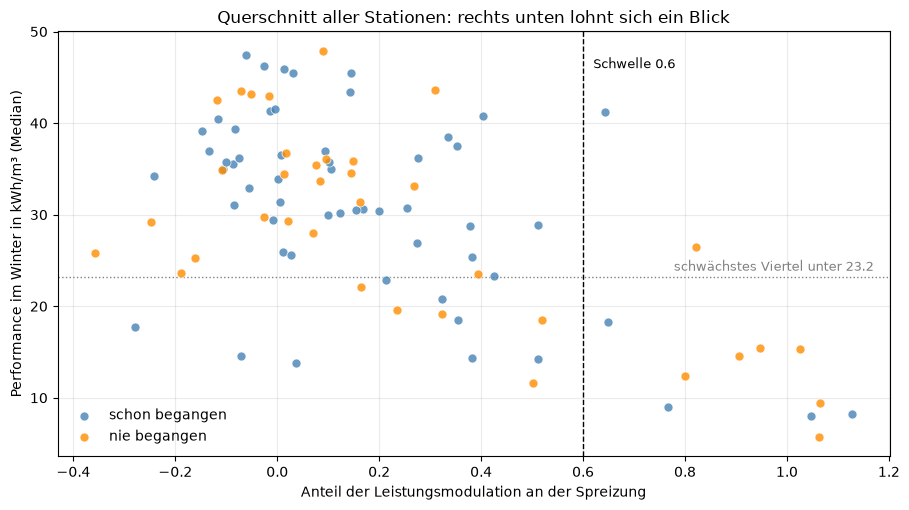

In [14]:
fig, ax = plt.subplots(figsize=(9.2, 5.2))
for maske, farbe, name in (
        (quer["begehung"], "steelblue", "schon begangen"),
        (~quer["begehung"], "darkorange", "nie begangen")):
    t = quer[maske]
    ax.scatter(t["anteil_mod_dt"], t["performance_median"], s=42,
               color=farbe, alpha=0.8, edgecolor="white", linewidth=0.6,
               label=name, zorder=3)
ax.axvline(fs.SCHWELLE_SPREIZUNG, color="black", lw=1.0, ls="--")
ax.axhline(r["grenze"], color="grey", lw=1.0, ls=":")
ax.text(fs.SCHWELLE_SPREIZUNG + 0.02, 46,
        f"Schwelle {fs.SCHWELLE_SPREIZUNG}", fontsize=9)
ax.text(1.17, r["grenze"] + 0.7,
        f"schwächstes Viertel unter {r['grenze']:.1f}", fontsize=9,
        color="grey", ha="right")
ax.set_xlabel("Anteil der Leistungsmodulation an der Spreizung")
ax.set_ylabel("Performance im Winter in kWh/m³ (Median)")
ax.set_title("Querschnitt aller Stationen: rechts unten lohnt sich ein Blick")
ax.legend(loc="lower left", frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / "querschnitt_screening.png", dpi=120)
plt.show()

In [15]:
vorschlag = quer[(quer["anteil_mod_dt"] > fs.SCHWELLE_SPREIZUNG)
                 & ~quer["begehung"]].sort_values("performance_median")
print(f"Auffaellig und noch nie begangen: {len(vorschlag)} Stationen")
print(vorschlag[["meter", "performance_median", "anteil_mod_dt", "streuung",
                 "leistung_p95", "stunden_winter"]].round(2)
      .to_string(index=False))

vorschlag.to_csv(OUT_DIR / "vorschlagsliste.csv", index=False)
winter.drop(columns=["notiz"]).to_csv(OUT_DIR / "wirkung_winter.csv",
                                      index=False)
quer.to_csv(OUT_DIR / "querschnitt_winter.csv", index=False)
tick(f"Tabellen geschrieben nach {OUT_DIR.relative_to(ROOT)}")

Auffaellig und noch nie begangen: 7 Stationen
   meter  performance_median  anteil_mod_dt  streuung  leistung_p95  stunden_winter
72135480                5.70           1.06      0.13          9.53            5686
72167793                9.42           1.07      0.18          9.41            2844
81050517               12.33           0.80      0.04        189.05            2158
72167777               14.54           0.91      0.20         14.31            4301
81062289               15.35           1.03      0.04        185.16            2158
68956360               15.47           0.95      0.16          7.22            3904
69513891               26.46           0.82      0.13         13.22            6360
[     5s] Tabellen geschrieben nach outputs/fallsammlung


- Sieben auffällige Stationen stehen in keiner Begehungsliste (`outputs/fallsammlung/vorschlagsliste.csv`). Zwei davon, 72167777 und 69513891, haben sich zusätzlich stark verändert.
- Das ist die bisher konkreteste Ausgabe des unüberwachten Strangs.

## Zusammenfassung & Bewertung

**Ergebnis**
- Der saisongleiche Schnitt dreht das Ergebnis um: naiv +1,28 (Kontrolle) gegen −0,29 (Begehung), im Winterschnitt −0,76 gegen +0,81. Das betrifft auch Notebook 11.
- Screening: zwölf Stationen regeln überwiegend über die Spreizung, zehn davon im schwächsten Viertel. Daraus sieben Vorschläge für nie begangene Stationen.

**Belastbar**
- Der methodische Punkt zum saisongleichen Vergleich und das Screening, weil beides reines Abzählen ist.

**Schwach**
- Die Rangfolge der Gruppen (+1,51, −0,35, −0,76) ist nur ein Muster: Cliffs Delta 0,36 bei p = 0,059 und 15 gegen 27 Stationen.
- Ein Fall mit +36 kWh/m³ trägt den Mittelwert.
- „Mechanisch“ hängt daran, was notiert wurde.

**Offen**
- Was steckt hinter den fünf Kontrollstationen mit starker Verbesserung?
- Prüfung der Vorschlagsliste vor Ort.